# Comparison with an off-the-shelf language model (v1)

*Run 20 Oct 2026 (run `20261020-123448`); paths adapted to this repository's layout on 23 Oct 2026.*

**The question.** Would an off-the-shelf language model find the same shared practice? A sentence-embedding model (all-mpnet-base-v2) turns each catalogue description into a list of 768 numbers, so that descriptions about similar things sit close together. We ask whether records grouped this way follow the collections they came from (ballads with ballads, films with films), or whether the groups cut across collections the way the masked method's practice groups do.

**What we expect.** The embedding groups should follow collection and subject far more closely than the masked groups, because the model reads what a record is about and the masking deliberately hides that.

**How the comparison is kept fair.**
1. Same text as the pilot: the description fields only, with the NLS stock sentences removed by the pilot's own `strip_boilerplate`.
2. Same records: the headline comparison uses the 901 records the pilot clustered (`practice-sample_…_20260708-152108.tsv`).
3. Same grouping method and settings: HDBSCAN with `MIN_CLUSTER_SIZE = 15` and `MIN_SAMPLES = 5`, run on a table of distances between records, exactly as in the pilot. Only the distances change: the pilot measured differences in each record's mix of clause types, and here we measure differences between embeddings.

**Two measures, both reported for embeddings and for the pilot.**
- *AMI with collection*: how closely the groups follow the collections. 0 means the groups ignore collection; 1 means they copy it exactly.
- *Same-collection neighbours*: for each record, of the 10 records closest to it, how many come from its own collection. This needs no grouping at all, so it is a check on the AMI.

**Run order.** Run the cells top to bottom. Step 4 (embedding) is the slow one: expect roughly 20–40 minutes for all 26,957 records on the processor alone, much less with a GPU. It saves a checkpoint, so a rerun skips it. For a quick trial first, set `TEST_N = 2000` in the configuration cell.

## Step 0 – Configuration

Every setting that might change lives here. `MODEL_NAME` is the embedding model: `all-mpnet-base-v2` is the most widely used general English model in the sentence-transformers library, open-weight, and gives 768 numbers per record. It reads at most 384 word-pieces (about 250–300 words); longer records are cut, and Step 4 reports how many.

In [1]:
from pathlib import Path
import random, sys, time, json, platform
import numpy as np
import pandas as pd

CODE_DIR    = Path.cwd()
SCRIPT_DIR  = CODE_DIR / ".."                              # the repository's script/ folder
CORPUS_XML  = SCRIPT_DIR / "data" / "nls-merged-corpus-v2.xml"
PILOT_CODE  = SCRIPT_DIR / "code"                          # for structural_masking_v1.py (read only)
PILOT_DATA  = SCRIPT_DIR / "derived-data"
PILOT_RUN   = "20260708-152108"                            # the published pilot run
PILOT_SAMPLE   = PILOT_DATA / f"practice-sample_nls-merged-corpus_{PILOT_RUN}.tsv"
PILOT_FEATURES = PILOT_DATA / f"structure-features_nls-merged-corpus_{PILOT_RUN}.tsv"
DERIVED     = CODE_DIR / "derived-data";   DERIVED.mkdir(exist_ok=True)
VIS         = CODE_DIR / "visualisations"; VIS.mkdir(exist_ok=True)

RANDOM_SEED = 42

# embedding model
MODEL_NAME     = "sentence-transformers/all-mpnet-base-v2"
MODEL_REVISION = None      # None = latest; the commit actually used is recorded in Step 4
BATCH_SIZE     = 32
DEVICE         = None      # None = let sentence-transformers choose (GPU if present)
TEST_N         = None      # e.g. 2000 for a quick trial on a random subset; None = all records

# grouping – the pilot's own settings (structure_difference_v2.ipynb)
MIN_CLUSTER_SIZE = 15
MIN_SAMPLES      = 5

# neighbours and the map
K_NEIGHBOURS    = 10       # "of the 10 closest records, how many share the collection"
UMAP_NEIGHBOURS = 15
UMAP_MIN_DIST   = 0.1
LEIDEN_RESOLUTION = 1.0    # whole-corpus grouping on the 10-nearest-neighbour network

random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
TS = time.strftime("%Y%m%d-%H%M%S")
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
for p in (CORPUS_XML, PILOT_CODE / "structural_masking_v1.py", PILOT_SAMPLE, PILOT_FEATURES):
    assert p.exists(), f"Missing input: {p.resolve()} – check the repository layout."
print("Run:", TS, "| Python", platform.python_version())

Run: 20261020-123448 | Python 3.11.14


## Step 1 – Load the records and their description text

Reads the merged corpus with the same parsing as the pilot, joins each record's description fields, and removes the NLS stock sentences with the pilot's `strip_boilerplate`. Titles and subject headings are left out, as in the pilot. Records with no description left after that are listed and dropped.

In [2]:
import xml.etree.ElementTree as ET
from collections import Counter
sys.path.insert(0, str(PILOT_CODE.resolve()))
import structural_masking_v1 as sm

NS = {"mc": "http://purl.org/nls-merged-corpus/1.0/"}

def load_records(path: Path) -> pd.DataFrame:
    """Parse the merged corpus; return record_id, collection and boilerplate-stripped description text.

    Description fields are matched by local name, so both dc: (Data Foundry) and dcterms: (MIA) are handled.
    """
    rows = []
    for _, d in ET.iterparse(str(path), events=("end",)):
        if not d.tag.endswith("Description"):
            continue
        descs = [e.text for e in d if e.tag.endswith("description") and e.text]
        coll = d.find("mc:collection", NS); rid = d.find("mc:record_id", NS)
        rows.append({"record_id": rid.text if rid is not None else "?",
                     "collection": coll.text if coll is not None else "?",
                     "text": sm.strip_boilerplate(" ".join(descs))})
        d.clear()
    return pd.DataFrame(rows)

t0 = time.time()
records = load_records(CORPUS_XML)
assert len(records) > 0, f"No records parsed from {CORPUS_XML}"
assert records["record_id"].is_unique, "Duplicate record_ids in the corpus"
print(f"Loaded {len(records):,} records in {time.time()-t0:.0f}s")

empty = records["text"].str.len() == 0
print(f"No description after stripping: {empty.sum()} records", dict(Counter(records.loc[empty, 'collection'])))
records = records.loc[~empty].reset_index(drop=True)
records["n_words"] = records["text"].str.split().str.len()
summary = records.groupby("collection").agg(records=("record_id", "size"),
                                            median_words=("n_words", "median")).sort_values("records", ascending=False)
print(f"Kept {len(records):,} records")
summary

Loaded 26,957 records in 4s
No description after stripping: 158 records {'eb': 139, 'hd': 1, 'mia': 18}
Kept 26,799 records


,records,median_words
collection,,
mia,23473,94.0
eb,2299,32.0
hd,536,123.0
tp,190,24.0
tb,91,19.0
sp,72,25.0
jw,62,3.0
fb,40,142.0
jk,23,15.0


In [3]:
# a few records from each collection, to see what the model will read
records.groupby("collection").head(1)[["record_id", "collection", "text"]].assign(text=lambda d: d["text"].str[:120])

,record_id,collection,text
0,eb_74891512,eb,Two ballads. Sweet Dundee - first line reads: As I walk'd out one morning across the v...
2299,fb_74570306,fb,Photograph of the Firth of Forth with artists' imaginative depiction of the completed ...
2339,hd_74601924,hd,There is no title attached to this sheet to clarify its provenance and context. It is ...
2875,ja_1005,ja,Originally Published 1682
2888,jk_74903852,jk,"Originally Published ca. 1772 Plans of farms in Golspie and Loth parishes, Sutherland,..."
2911,jw_74400001,jw,Originally Published 1828
2973,mia_0001,mia,"non-fiction; documentary [filmed by Stanley L. Russell, Thames and Clyde]. The Botanic..."
26446,sp_74506106,sp,Date of event depicted: between 1917 and 1936 Coloured poster showing breast-feeding t...
26518,tb_74585060,tb,Date of event depicted: 1879 Photograph of wrecked piers after collapse of part of the...
26609,tp_74508590,tp,Originally published: between 1868 and 1869 Actor in stage costume as a clown..


## Step 2 – Load the pilot's 901 records and their practice groups

The pilot clustered a sample capped at 150 records per collection (so that small collections appear) and assigned each to a practice group (`P7`, `P11`, …) or to `noise` (not grouped). We also load each record's mix of clause types (the shares the pilot measured distances on), so the neighbour measure can be computed for the pilot too.

In [4]:
pilot = pd.read_csv(PILOT_SAMPLE, sep="\t", dtype=str)
feats = pd.read_csv(PILOT_FEATURES, sep="\t")
share_cols = [c for c in feats.columns if c.startswith("share_")]
pilot = pilot.merge(feats[["record_id"] + share_cols], on="record_id", how="left")
assert pilot[share_cols].notna().all().all(), "Some pilot records have no clause-type shares"

in_corpus = pilot["record_id"].isin(records["record_id"])
assert in_corpus.all(), f"{(~in_corpus).sum()} pilot records missing from the corpus text: {pilot.loc[~in_corpus,'record_id'].tolist()[:5]}"
print(f"Pilot sample: {len(pilot)} records, {pilot['practice_cluster'].nunique()} labels (incl. noise)")
print("By collection:", dict(Counter(pilot["collection"])))
print(f"Pilot noise share: {(pilot['practice_cluster']=='noise').mean():.0%}")

Pilot sample: 901 records, 14 labels (incl. noise)
By collection: {'eb': 150, 'fb': 40, 'hd': 150, 'ja': 13, 'jk': 23, 'jw': 62, 'mia': 150, 'sp': 72, 'tb': 91, 'tp': 150}
Pilot noise share: 17%


## Step 3 – Optional quick trial

If `TEST_N` is set, embed only a random subset (always keeping the 901 pilot records, so Steps 5–7 still work). Leave `TEST_N = None` for the real run.

In [5]:
if TEST_N:
    keep = set(pilot["record_id"])
    rest = records.loc[~records["record_id"].isin(keep)].sample(n=max(0, TEST_N - len(keep)), random_state=RANDOM_SEED)
    to_embed = pd.concat([records.loc[records["record_id"].isin(keep)], rest]).reset_index(drop=True)
    print(f"TRIAL RUN: embedding {len(to_embed):,} of {len(records):,} records")
else:
    to_embed = records
    print(f"Full run: embedding all {len(to_embed):,} records")

Full run: embedding all 26,799 records


## Step 4 – Embed every description (slow; saves a checkpoint)

Each description becomes 768 numbers, scaled to length 1 so that closeness is measured by angle (cosine). The result is saved as a `.npy` file with a matching list of record ids; if a checkpoint for the same model and the same records exists, it is loaded instead. Also reports how many records are longer than the model can read (it reads only their opening).

In [6]:
import torch
from sentence_transformers import SentenceTransformer
import sentence_transformers

torch.manual_seed(RANDOM_SEED)
model = SentenceTransformer(MODEL_NAME, revision=MODEL_REVISION, device=DEVICE)
try:
    from huggingface_hub import model_info
    model_commit = MODEL_REVISION or model_info(MODEL_NAME).sha
except Exception as e:
    model_commit = f"unknown ({type(e).__name__})"
print(f"Model {MODEL_NAME} @ {model_commit} | max length {model.max_seq_length} word-pieces | device {model.device}")

n_tokens = np.array([len(model.tokenizer(t, add_special_tokens=True)["input_ids"]) for t in to_embed["text"]])
cut = n_tokens > model.max_seq_length
print(f"Records longer than the model reads: {cut.sum():,} of {len(cut):,} ({cut.mean():.0%})")
print(pd.Series(cut, index=to_embed["collection"].values).groupby(level=0).mean().round(2).rename("share cut").to_dict())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model sentence-transformers/all-mpnet-base-v2 @ e8c3b32edf5434bc2275fc9bab85f82640a19130 | max length 384 word-pieces | device cuda:0


Token indices sequence length is longer than the specified maximum sequence length for this model (633 > 384). Running this sequence through the model will result in indexing errors


Records longer than the model reads: 5,427 of 26,799 (20%)
{'eb': 0.0, 'fb': 0.08, 'hd': 0.0, 'ja': 0.0, 'jk': 0.0, 'jw': 0.0, 'mia': 0.23, 'sp': 0.0, 'tb': 0.0, 'tp': 0.0}


In [7]:
model_tag = MODEL_NAME.split("/")[-1]
ids_key = f"{len(to_embed)}"
existing = sorted(DERIVED.glob(f"embeddings_{model_tag}_n{ids_key}_*.npy"))
if existing:
    ckpt = existing[-1]
    E = np.load(ckpt)
    ids = pd.read_csv(ckpt.with_suffix(".ids.tsv"), sep="\t", dtype=str)["record_id"]
    assert ids.tolist() == to_embed["record_id"].tolist(), f"Checkpoint {ckpt.name} lists different records – delete or move it to attic/"
    print(f"Loaded checkpoint {ckpt.name}: {E.shape}")
else:
    texts = to_embed["text"].tolist(); total = len(texts); chunks = []; t0 = time.time()
    step = BATCH_SIZE * 20
    for start in range(0, total, step):
        chunks.append(model.encode(texts[start:start+step], batch_size=BATCH_SIZE,
                                   normalize_embeddings=True, show_progress_bar=False))
        n = min(start + step, total); el = time.time() - t0; rate = n / el
        print(f"{n}/{total} ({100*n/total:.0f}%) | elapsed {el:.0f}s | rate {rate:.0f} rec/s | ETA {(total-n)/rate:.0f}s")
    E = np.vstack(chunks).astype(np.float32)
    ckpt = DERIVED / f"embeddings_{model_tag}_n{ids_key}_{TS}.npy"
    np.save(ckpt, E)
    to_embed[["record_id", "collection"]].to_csv(ckpt.with_suffix(".ids.tsv"), sep="\t", index=False)
    print(f"Saved {ckpt.name}")
assert E.shape == (len(to_embed), model.get_sentence_embedding_dimension()), f"Unexpected shape {E.shape}"
assert np.allclose(np.linalg.norm(E, axis=1), 1, atol=1e-3), "Embeddings are not unit length"
row_of = {rid: i for i, rid in enumerate(to_embed["record_id"])}

640/26799 (2%) | elapsed 2s | rate 264 rec/s | ETA 99s
1280/26799 (5%) | elapsed 4s | rate 312 rec/s | ETA 82s
1920/26799 (7%) | elapsed 6s | rate 320 rec/s | ETA 78s
2560/26799 (10%) | elapsed 9s | rate 278 rec/s | ETA 87s
3200/26799 (12%) | elapsed 15s | rate 216 rec/s | ETA 109s
3840/26799 (14%) | elapsed 23s | rate 164 rec/s | ETA 140s
4480/26799 (17%) | elapsed 32s | rate 138 rec/s | ETA 162s
5120/26799 (19%) | elapsed 39s | rate 130 rec/s | ETA 166s
5760/26799 (21%) | elapsed 51s | rate 114 rec/s | ETA 185s
6400/26799 (24%) | elapsed 60s | rate 107 rec/s | ETA 190s
7040/26799 (26%) | elapsed 72s | rate 98 rec/s | ETA 201s
7680/26799 (29%) | elapsed 78s | rate 98 rec/s | ETA 195s
8320/26799 (31%) | elapsed 81s | rate 103 rec/s | ETA 180s
8960/26799 (33%) | elapsed 84s | rate 107 rec/s | ETA 167s
9600/26799 (36%) | elapsed 87s | rate 110 rec/s | ETA 156s
10240/26799 (38%) | elapsed 91s | rate 112 rec/s | ETA 147s
10880/26799 (41%) | elapsed 95s | rate 115 rec/s | ETA 139s
11520/267

/tmp/ipykernel_705/2528831176.py:23: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  assert E.shape == (len(to_embed), model.get_sentence_embedding_dimension()), f"Unexpected shape {E.shape}"


## Step 5 – Like for like: group the pilot's 901 records by embedding

Distances between the 901 records' embeddings (1 minus cosine similarity), then HDBSCAN with the pilot's settings. HDBSCAN may leave records ungrouped (`noise`), as in the pilot; the share left out is reported.

In [8]:
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_mutual_info_score as ami

Es = E[[row_of[r] for r in pilot["record_id"]]]
D_emb = np.clip(1.0 - Es @ Es.T, 0, None); np.fill_diagonal(D_emb, 0.0)
hdb = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES, metric="precomputed").fit(D_emb.astype(np.float64))
pilot["embedding_cluster"] = [("noise" if l == -1 else f"E{l}") for l in hdb.labels_]
n_emb = pilot["embedding_cluster"].nunique() - int("noise" in set(pilot["embedding_cluster"]))
n_pil = pilot["practice_cluster"].nunique() - int("noise" in set(pilot["practice_cluster"]))
print(f"Embedding groups: {n_emb} | noise {(pilot['embedding_cluster']=='noise').mean():.0%}")
print(f"Pilot practice groups: {n_pil} | noise {(pilot['practice_cluster']=='noise').mean():.0%}")

Embedding groups: 10 | noise 44%
Pilot practice groups: 13 | noise 17%


/home/jwbaker/miniforge3/envs/dh-soton/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [9]:
def composition(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """One row per group: size, number of collections, and the collections it contains."""
    rows = []
    for lab, g in df.groupby(col):
        c = Counter(g["collection"])
        rows.append({"group": lab, "size": len(g), "n_collections": len(c),
                     "collections": ", ".join(f"{k}:{v}" for k, v in c.most_common())})
    return pd.DataFrame(rows).sort_values("size", ascending=False).reset_index(drop=True)

emb_groups = composition(pilot, "embedding_cluster")
emb_groups

,group,size,n_collections,collections
0,noise,395,6,"tp:116, mia:115, eb:76, hd:74, sp:10, tb:4"
1,E7,76,1,hd:76
2,E0,75,2,"jw:62, ja:13"
3,E6,74,1,eb:74
4,E9,62,1,sp:62
5,E4,52,1,tb:52
6,E2,40,1,fb:40
7,E1,35,1,mia:35
8,E3,35,1,tb:35
9,E8,34,1,tp:34


## Step 6 – AMI with collection: embeddings against the pilot, on the same records

Two versions. *All records* treats `noise` as one more group (this is the stricter one). *Grouped records only* drops records that either method left ungrouped, so both are scored on the same records. The pilot's clause-level figure from the stage-2 notebook (0.269, clause types against collection) is shown for reference; it measures something different.

In [10]:
both = (pilot["embedding_cluster"] != "noise") & (pilot["practice_cluster"] != "noise")
ami_table = pd.DataFrame([
    {"measure": "AMI with collection, all 901 records (noise as a group)",
     "embeddings": ami(pilot["collection"], pilot["embedding_cluster"]),
     "pilot (masked)": ami(pilot["collection"], pilot["practice_cluster"])},
    {"measure": f"AMI with collection, records grouped by both ({both.sum()})",
     "embeddings": ami(pilot.loc[both, "collection"], pilot.loc[both, "embedding_cluster"]),
     "pilot (masked)": ami(pilot.loc[both, "collection"], pilot.loc[both, "practice_cluster"])},
    {"measure": "Groups containing more than one collection",
     "embeddings": int((emb_groups.query("group != 'noise'")["n_collections"] > 1).sum()),
     "pilot (masked)": int((composition(pilot, "practice_cluster").query("group != 'noise'")["n_collections"] > 1).sum())},
])
print("Reference: stage-2 notebook, clause types against collection, AMI 0.269 (a different measure).")
ami_table.round(3)

Reference: stage-2 notebook, clause types against collection, AMI 0.269 (a different measure).


,measure,embeddings,pilot (masked)
0,"AMI with collection, all 901 records (noise as a group)",0.691,0.600
1,"AMI with collection, records grouped by both (478)",0.954,0.716
2,Groups containing more than one collection,1.000,9.000


## Step 7 – Same-collection neighbours, on the same records

For each of the 901 records, take the 10 records closest to it and count how many come from the same collection. *Chance* is what you would expect if neighbours were picked at random from the sample. Embeddings use cosine distance; the pilot uses the Jensen–Shannon distance between clause-type mixes, as in the pilot notebook.

In [11]:
from scipy.spatial.distance import pdist, squareform

P = pilot[share_cols].to_numpy(dtype=float)
D_pil = squareform(pdist(P, metric="jensenshannon")); D_pil[np.isnan(D_pil)] = 0.0

def same_collection_share(D: np.ndarray, colls: np.ndarray, k: int) -> np.ndarray:
    """For each row, the share of its k nearest other rows (by distance matrix D) in the same collection."""
    D = D.copy(); np.fill_diagonal(D, np.inf)
    rng = np.random.default_rng(RANDOM_SEED)
    D = D + rng.uniform(0, 1e-9, D.shape)          # break exact ties (identical profiles) at random, reproducibly
    nn = np.argsort(D, axis=1)[:, :k]
    return (colls[nn] == colls[:, None]).mean(axis=1)

colls = pilot["collection"].to_numpy()
n = len(colls); size = pilot["collection"].map(Counter(colls)).to_numpy()
pilot["same_coll_emb"] = same_collection_share(D_emb, colls, K_NEIGHBOURS)
pilot["same_coll_pilot"] = same_collection_share(D_pil, colls, K_NEIGHBOURS)
pilot["same_coll_chance"] = (size - 1) / (n - 1)
nbr = pilot.groupby("collection")[["same_coll_emb", "same_coll_pilot", "same_coll_chance"]].mean()
nbr["records"] = pilot.groupby("collection").size()
nbr.loc["ALL (901)"] = list(pilot[["same_coll_emb", "same_coll_pilot", "same_coll_chance"]].mean()) + [n]
nbr.columns = ["embeddings", "pilot (masked)", "chance", "records"]
print(f"Of each record's {K_NEIGHBOURS} closest records, the share from its own collection:")
nbr.round(2)

Of each record's 10 closest records, the share from its own collection:


,embeddings,pilot (masked),chance,records
collection,,,,
eb,0.98,0.56,0.17,150.0
fb,1.00,0.67,0.04,40.0
hd,0.99,0.59,0.17,150.0
ja,1.00,0.16,0.01,13.0
jk,1.00,1.00,0.02,23.0
jw,1.00,0.78,0.07,62.0
mia,0.89,0.81,0.17,150.0
sp,1.00,0.34,0.08,72.0
tb,1.00,0.53,0.10,91.0


## Step 8 – Where do the pilot's cross-collection groups go?

For each pilot practice group that spans more than one collection, which embedding groups do its members fall into? If the embeddings split each one up by collection, that shows what the masking adds.

In [12]:
rows = []
for lab, g in pilot.query("practice_cluster != 'noise'").groupby("practice_cluster"):
    if g["collection"].nunique() < 2:
        continue
    split = g.groupby("embedding_cluster")["collection"].agg(lambda s: ", ".join(f"{k}:{v}" for k, v in Counter(s).most_common()))
    rows.append({"pilot group": lab, "size": len(g),
                 "collections": ", ".join(f"{k}:{v}" for k, v in Counter(g["collection"]).most_common()),
                 "embedding groups it falls into": "; ".join(f"{e} ({c})" for e, c in split.items())})
pd.DataFrame(rows).sort_values("size", ascending=False)

,pilot group,size,collections,embedding groups it falls into
7,P7,171,"tb:91, sp:57, tp:18, eb:4, hd:1","E3 (tb:35); E4 (tb:52); E6 (eb:1); E8 (tp:16); E9 (sp:48); noise (sp:9, tb:4, eb:3, tp..."
2,P11,167,"hd:99, eb:67, fb:1","E2 (fb:1); E6 (eb:40); E7 (hd:55); noise (hd:44, eb:27)"
8,P9,80,"eb:42, hd:22, mia:15, fb:1","E1 (mia:1); E2 (fb:1); E6 (eb:14); E7 (hd:12); noise (eb:28, mia:14, hd:10)"
4,P3,79,"jw:62, ja:13, eb:4","E0 (jw:62, ja:13); E6 (eb:1); noise (eb:3)"
3,P12,52,"fb:36, hd:16",E2 (fb:36); E7 (hd:5); noise (hd:11)
6,P6,41,"tp:40, mia:1","E8 (tp:2); noise (tp:38, mia:1)"
1,P10,26,"eb:22, hd:4","E6 (eb:14); E7 (hd:1); noise (eb:8, hd:3)"
5,P4,25,"tp:13, sp:12",E8 (tp:4); E9 (sp:12); noise (tp:9)
0,P1,24,"jk:23, mia:1",E5 (jk:23); noise (mia:1)


## Step 9 – Read some records (failure modes and what the groups are about)

Three records from each of the five largest embedding groups, so you can see what the model is grouping on (subject? collection template? length?). Read these before trusting any number above.

In [13]:
text_of = dict(zip(records["record_id"], records["text"]))
for lab in emb_groups.query("group != 'noise'")["group"].head(5):
    g = pilot.query("embedding_cluster == @lab")
    print(f"\n=== {lab}: {len(g)} records | {', '.join(f'{k}:{v}' for k,v in Counter(g['collection']).most_common())}")
    for rid in g["record_id"].sample(min(3, len(g)), random_state=RANDOM_SEED):
        print(f"  {rid}: {text_of[rid][:160]}")


=== E7: 76 records | hd:76
  hd_74635340: This drawing of the priory at Pittenweem was made in 1783, and appeared in volume I of Captain Francis Grose's book, 'The Antiquities of Scotland', which was pu
  hd_74601902: This is a sketch of a sculpted stone in Coupar Angus, Perthshire. The sculpture on the stone appears to be of a royal or heraldic shield, displaying the lion ra
  hd_74601920: There is no information attached to this rubbing at all. It is to be found amongst five other views of Whithorn Priory, most were created in 1811. Hutton seems 

=== E0: 75 records | jw:62, ja:13
  ja_1009: Originally Published 1684
  jw_74400057: Originally Published 1820
  ja_1015: Originally Published 1682

=== E6: 74 records | eb:74
  eb_74891710: First line reads: Attend, you poor of England, and listen unto me. In one column..
  eb_74894068: Three ballads. [P]arson and Quaker - first line reads: A jolly faced parson once happened to pop. Though fortune darkly o'er me frowns - first line reads

## Step 10 – Whole corpus: neighbours and groups on all records

The same neighbour count on every embedded record, plus a grouping of the whole corpus in the way Grandjean (2026) builds his maps: link each record to its 10 nearest, then find communities in that network with Leiden. MIA is 87% of the corpus, so read the per-collection rows, not only the overall figure.

In [14]:
from sklearn.neighbors import NearestNeighbors
import igraph as ig, leidenalg

t0 = time.time()
nn = NearestNeighbors(n_neighbors=K_NEIGHBOURS + 1, metric="cosine").fit(E)
_, idx = nn.kneighbors(E)
idx = idx[:, 1:]                                         # drop the record itself
print(f"Nearest neighbours for {len(E):,} records in {time.time()-t0:.0f}s")
ec = to_embed["collection"].to_numpy()
full_nbr = pd.DataFrame({"collection": ec, "same": (ec[idx] == ec[:, None]).mean(axis=1)})
csize = pd.Series(Counter(ec)); N = len(ec)
full_tab = full_nbr.groupby("collection")["same"].mean().to_frame("embeddings")
full_tab["chance"] = (csize - 1) / (N - 1); full_tab["records"] = csize
full_tab.loc["ALL"] = [full_nbr["same"].mean(), ((csize * (csize - 1)).sum() / (N * (N - 1))), N]
full_tab.sort_values("records", ascending=False).round(2)

Nearest neighbours for 26,799 records in 13s


,embeddings,chance,records
collection,,,
ALL,1.00,0.78,26799.0
mia,1.00,0.88,23473.0
eb,0.99,0.09,2299.0
hd,0.96,0.02,536.0
tp,0.88,0.01,190.0
tb,1.00,0.00,91.0
sp,0.99,0.00,72.0
jw,1.00,0.00,62.0
fb,0.99,0.00,40.0


In [15]:
edges = {(min(i, j), max(i, j)) for i in range(len(idx)) for j in idx[i]}
g = ig.Graph(n=len(E), edges=list(edges))
part = leidenalg.find_partition(g, leidenalg.RBConfigurationVertexPartition,
                                resolution_parameter=LEIDEN_RESOLUTION, seed=RANDOM_SEED)
to_embed = to_embed.assign(leiden=[f"L{m}" for m in part.membership])
print(f"Leiden: {len(part)} communities on {g.vcount():,} records and {g.ecount():,} links")
print(f"AMI(Leiden community, collection), all records: {ami(to_embed['collection'], to_embed['leiden']):.3f}")
no_mia = to_embed["collection"] != "mia"
print(f"AMI(Leiden community, collection), without MIA ({no_mia.sum():,} records): "
      f"{ami(to_embed.loc[no_mia,'collection'], to_embed.loc[no_mia,'leiden']):.3f}")
mixed = to_embed.groupby("leiden")["collection"].nunique()
print(f"Communities with more than one collection: {(mixed > 1).sum()} of {len(mixed)}")

Leiden: 76 communities on 26,799 records and 214,740 links
AMI(Leiden community, collection), all records: 0.247
AMI(Leiden community, collection), without MIA (3,326 records): 0.946
Communities with more than one collection: 13 of 76


## Step 11 – The two-panel figure

UMAP map of the 901 pilot records from their embeddings. Left: marked by collection. Right: the same points marked by the pilot's practice group. Each category has its own marker shape as well as its own colour, so nothing depends on colour alone. A third figure maps the whole corpus by collection.

/home/jwbaker/miniforge3/envs/dh-soton/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved embeddings-vs-practice_umap_nls-merged-corpus_20261020-123448.png


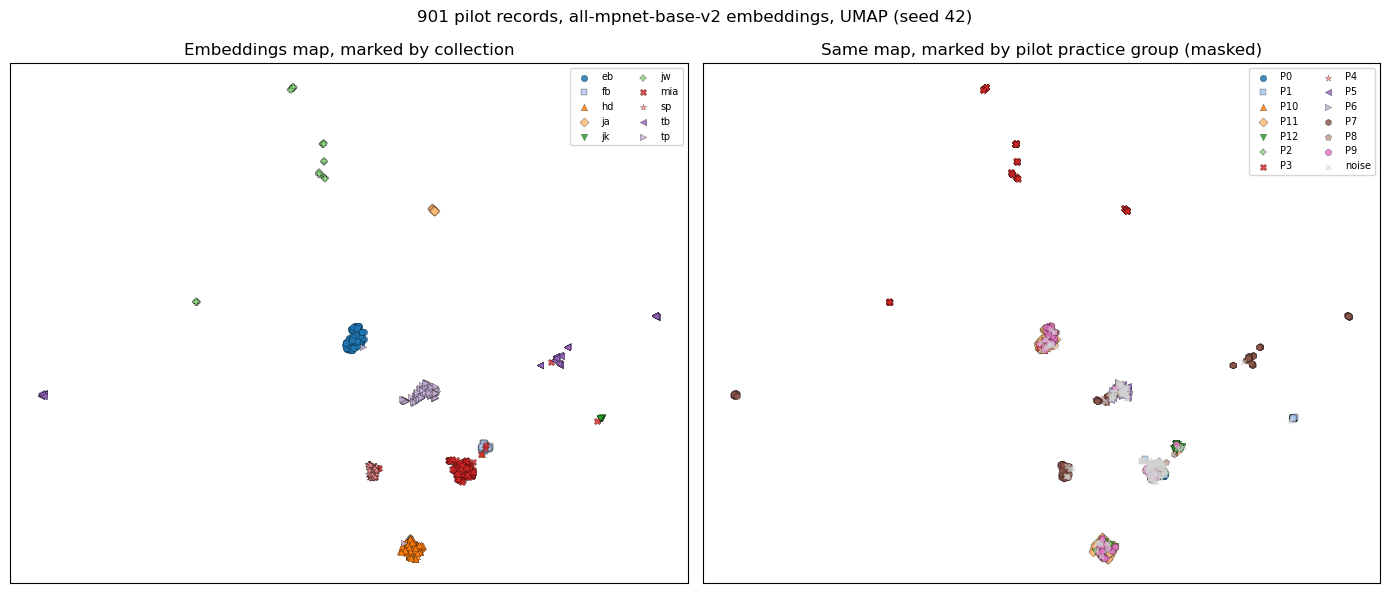

In [16]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(n_neighbors=UMAP_NEIGHBOURS, min_dist=UMAP_MIN_DIST, metric="cosine", random_state=RANDOM_SEED)
XY = reducer.fit_transform(Es)
pilot["umap_x"], pilot["umap_y"] = XY[:, 0], XY[:, 1]

MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "p", "8", "d", "H"]
def scatter_by(ax, labels, title):
    """Plot the UMAP points with one marker shape and colour per label; noise as grey crosses."""
    cmap = plt.get_cmap("tab20")
    for k, lab in enumerate(sorted(set(labels), key=lambda s: (s == "noise", s))):
        m = np.asarray(labels) == lab
        if lab == "noise":
            ax.scatter(XY[m, 0], XY[m, 1], c="lightgrey", marker="x", s=12, label="noise", alpha=.6)
        else:
            ax.scatter(XY[m, 0], XY[m, 1], color=cmap(k % 20), marker=MARKERS[k % len(MARKERS)], s=22,
                       label=lab, alpha=.85, edgecolor="k", linewidth=.2)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=7, ncol=2, loc="best")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
scatter_by(ax[0], pilot["collection"].tolist(), "Embeddings map, marked by collection")
scatter_by(ax[1], pilot["practice_cluster"].tolist(), "Same map, marked by pilot practice group (masked)")
fig.suptitle(f"901 pilot records, {MODEL_NAME.split('/')[-1]} embeddings, UMAP (seed {RANDOM_SEED})")
fig.tight_layout()
fig_path = VIS / f"embeddings-vs-practice_umap_nls-merged-corpus_{TS}.png"
fig.savefig(fig_path, dpi=200); print("Saved", fig_path.name)
plt.show()

/home/jwbaker/miniforge3/envs/dh-soton/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved embeddings_umap_all-records_nls-merged-corpus_20261020-123448.png


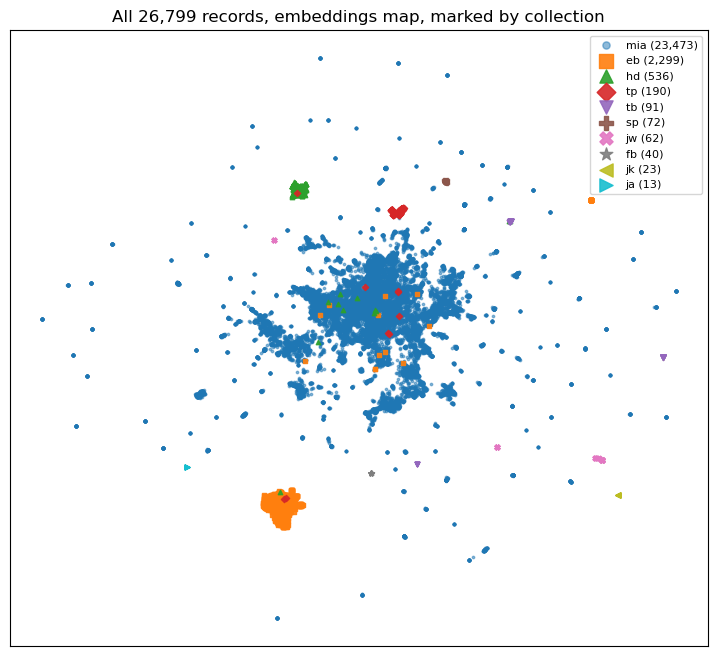

In [17]:
XY_all = umap.UMAP(n_neighbors=UMAP_NEIGHBOURS, min_dist=UMAP_MIN_DIST, metric="cosine",
                   random_state=RANDOM_SEED).fit_transform(E)
fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.get_cmap("tab10")
for k, c in enumerate(csize.sort_values(ascending=False).index):
    m = ec == c
    ax.scatter(XY_all[m, 0], XY_all[m, 1], s=3 if c == "mia" else 10, color=cmap(k % 10),
               marker=MARKERS[k % len(MARKERS)], label=f"{c} ({m.sum():,})", alpha=.5 if c == "mia" else .9)
ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=3, fontsize=8)
ax.set_title(f"All {len(E):,} records, embeddings map, marked by collection")
fig_all = VIS / f"embeddings_umap_all-records_nls-merged-corpus_{TS}.png"
fig.savefig(fig_all, dpi=200); print("Saved", fig_all.name); plt.show()

## Step 12 – Save the results

Writes the record-level table (the 901 records with both groupings, neighbour shares and map positions), the whole-corpus Leiden communities, and a short summary with every number above and the settings used.

In [18]:
out_rec = DERIVED / f"embeddings-vs-practice_nls-merged-corpus_{TS}.tsv"
pilot.drop(columns=share_cols).to_csv(out_rec, sep="\t", index=False)
out_leiden = DERIVED / f"embeddings-leiden_nls-merged-corpus_{TS}.tsv"
to_embed[["record_id", "collection", "leiden"]].to_csv(out_leiden, sep="\t", index=False)

summary = {
    "run": TS, "trial_run": bool(TEST_N), "records_embedded": int(len(E)),
    "model": MODEL_NAME, "model_commit": model_commit, "sentence_transformers": sentence_transformers.__version__,
    "records_cut_by_model_length": int(cut.sum()),
    "pilot_run": PILOT_RUN, "hdbscan": {"min_cluster_size": MIN_CLUSTER_SIZE, "min_samples": MIN_SAMPLES},
    "k_neighbours": K_NEIGHBOURS, "seed": RANDOM_SEED,
    "ami_901": ami_table.set_index("measure").round(4).to_dict(orient="index"),
    "same_collection_neighbours_901": nbr.round(4).to_dict(orient="index"),
    "same_collection_neighbours_all": full_tab.round(4).to_dict(orient="index"),
    "leiden_communities": len(part),
    "ami_leiden_all": round(ami(to_embed["collection"], to_embed["leiden"]), 4),
}
out_sum = DERIVED / f"embeddings-summary_nls-merged-corpus_{TS}.json"
out_sum.write_text(json.dumps(summary, indent=2, default=str))
for p in (out_rec, out_leiden, out_sum):
    print("Wrote", p.name)

Wrote embeddings-vs-practice_nls-merged-corpus_20261020-123448.tsv
Wrote embeddings-leiden_nls-merged-corpus_20261020-123448.tsv
Wrote embeddings-summary_nls-merged-corpus_20261020-123448.json


## Step 13 – The two methods side by side

This cell prints the AMI with collection for the embeddings and for the masked method on the same 901 records, side by side.


In [19]:
COMPARE_AGAINST = "same_records"   # "same_records" (pilot groups on the same 901) or "clause_figure" (0.269)
emb_ami = ami(pilot["collection"], pilot["embedding_cluster"])
ref = ami(pilot["collection"], pilot["practice_cluster"]) if COMPARE_AGAINST == "same_records" else 0.269
print(f"Embeddings, AMI with collection (901 records): {emb_ami:.3f}")
print(f"Pilot figure used for comparison ({COMPARE_AGAINST}): {ref:.3f}")
print(f"Same-collection neighbours, embeddings {nbr.loc['ALL (901)','embeddings']:.2f} vs pilot {nbr.loc['ALL (901)','pilot (masked)']:.2f} (chance {nbr.loc['ALL (901)','chance']:.2f})")

Embeddings, AMI with collection (901 records): 0.691
Pilot figure used for comparison (same_records): 0.600
Same-collection neighbours, embeddings 0.97 vs pilot 0.66 (chance 0.13)
